# Sentinel images

**This notebook was developed in order to learn how to use the openeo api to download sentinel images. Specifically we will use here Sentinel 2**

## 1. Set Up

### 1.1 Libraries

Let's install the libraries

In [1]:
from google.colab import drive
drive.mount("/content/gdrive")

%cd "/content/gdrive/MyDrive/JUAN ESTEBAN/Projects/Satellite-imagery/"

Mounted at /content/gdrive
/content/gdrive/.shortcut-targets-by-id/17ZZvrpCMvFGyf0rJgJM7azp57E0zsZlI/JUAN ESTEBAN/Projects/Satellite-imagery


Now check the dir you are in and install the libraries from `requirements.txt`

In [ ]:
!ls

data  modules  notebooks  README.md  requirements.txt  src


In [2]:
!pip install --quiet openeo xarray rioxarray folium matplotlib-scalebar

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 303.0/303.0 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 40.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.0/236.0 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.3 MB/s eta 0:00:00


Now, let's import the libraries

In [3]:
# Map observation
import folium as fl

# Data access to CDSE
import openeo
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import requests
import pandas as pd
import os
from pathlib import Path
from time import time
import datetime

# Image processing
from scipy.ndimage import gaussian_filter
import scipy.optimize as optimization
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.animation as animation
from IPython.display import display, HTML
from numpy.linalg import svd
from skimage import filters, img_as_ubyte
from skimage.metrics import structural_similarity
from skimage.morphology import disk,area_closing, erosion, dilation
from skimage.measure import label
from scipy.spatial.distance import euclidean

Finally, create a variable for the path to follow

In [4]:
general_path = Path("./")

### 1.3 Location

In [5]:
locations_info = {
    "latitude": [
                 4.7110,
                 ],
    "longitude": [
                  -74.0721,
                  ],
    "start_date": [
                   "2024-11-01",
                   ],
    "end_date": [
                 "2024-12-01",
                 ],
    "obs_date": [
                 "2024-11-03",
                 ]
}

df_locations = pd.DataFrame(locations_info, index = [
                      "Bogotá",
                      ]
                            )

In [6]:
df_locations

,latitude,longitude,start_date,end_date,obs_date
Bogotá,4.711,-74.0721,2024-11-01,2024-12-01,2024-11-03


In [7]:
location_name = "Bogotá"
location_data = df_locations.loc[location_name]

coordinates = {"latitude": location_data["latitude"],
               "longitude": location_data["longitude"]} #The coordinates are written in the EPSG:4386 format (also called wgs84).
dates_range = [location_data["start_date"], location_data["end_date"]]
resolution = 20 #meters

Create the area variables for asking the region to observe to the [OpenEO](https://dataspace.copernicus.eu/analyse/apis/openeo-api) API

In [8]:
area_of_obs = {}
area_of_obs["west"] = coordinates["longitude"]-0.02
area_of_obs["south"] = coordinates["latitude"]-0.01
area_of_obs["east"] = coordinates["longitude"]+0.02
area_of_obs["north"] = coordinates["latitude"]+0.01

Let's check the location using the given coordinates with `folium`

In [11]:
m = fl.Map(max_bounds = True,
           location = [
               coordinates["latitude"]-30,
               coordinates["longitude"]
           ],
           zoom_start = 15,
           min_lat = area_of_obs["south"],
           max_lat = area_of_obs["north"],
           min_lon = area_of_obs["west"],
           max_lon = area_of_obs["east"]
           )
fl.TileLayer(
        "Esri.WorldImagery").add_to(m)

m

## 2. Copernicus

### 2.1 Client credentials

In [ ]:
# Copernicus Data Space Ecosystem (CDSE) client credentials
client_id = "client_id"
client_secret = "client_secret"

connection = openeo.connect(url="openeo.dataspace.copernicus.eu")
connection.authenticate_oidc_client_credentials(
    client_id=client_id,
    client_secret=client_secret,
)


<Connection to 'https://openeo.dataspace.copernicus.eu/openeo/1.2/' with OidcBearerAuth>

### 2.2 Access and Download

Create the folders for saving the images

In [ ]:
folder_out = general_path / ('data/downloaded/'+location_name+"/")
images_out = folder_out / "Results/"

# Creation of the folder for saving the data
if not os.path.exists(folder_out):
    os.makedirs(folder_out)
if not os.path.exists(images_out):
    os.makedirs(images_out)

Define a variable for saving the process data in the `nc` format

In [ ]:
data_out = folder_out / (location_name+".nc")

Select the bands you want to download

In [ ]:
bands = ["B04", "B03", "B02", "B11", "B12", "sunZenithAngles", "viewZenithMean", "sunAzimuthAngles", "viewAzimuthMean"]

Now, let's define a routine that downloads only the data that is not already downloaded, i.e., to keep the dates you have downloaded already and add new ones for an augmented date range in case the user needs it. The products to download can be found [here](https://openeo.dataspace.copernicus.eu/)

In [ ]:
def ask_openeo(dates_range: list[int],
               area_of_obs: dict[str, float],
               bands: list[str],
               product: str = "SENTINEL2_L1C",
               max_cloud_cover: int = 100,
               resolution: int = 10) -> openeo.rest.datacube.DataCube:
  """
  Function for sending the query to the openeo api.
  Args:
    dates_range (list): Range of dates to be downloadde.
    area_of_obs (dict): Dictionary containing the latitude and longitude coordinates of the location you are interested in.
    band (list[str]): List containing the bands to be asked to openeo.
    product (str): Copernicus missions product selected for the images to be downloaded according the previous hyperparameters.
    max_cloud_cover (int): Cloud coverage over the whole tile (which means you can have a cloud cover of 100% in your image section even though there is a low cloud cover over all the tile).
    resolution (int): Number in meters to determines the resolution resampling of the satellite image.
  Result:
    output (openeo.rest.datacube.DataCube)
  """

  collection = connection.load_collection(
        product,
        temporal_extent=dates_range,
        spatial_extent={
            "west": area_of_obs["west"],
            "south": area_of_obs["south"],
            "east": area_of_obs["east"],
            "north": area_of_obs["north"],
            "crs": "EPSG:4326",
        },
        bands=bands,
        max_cloud_cover=100, #Maximum cloud cover FOR THE WHOLE TILE (the image could be covered by clouds even if this parameter is low)
    )


  # Resample to 60m resolution
  resampled_data = collection.resample_spatial(resolution=resolution)

  return resampled_data

#################################################################
# In case the data has not been created, download the images.
#################################################################

if not os.path.exists(data_out):
    print("Downloading dates:", dates_range)
    s2_cube = ask_openeo(dates_range = dates_range,
                         area_of_obs = area_of_obs,
                         bands = bands,
                         resolution = resolution)
    s2_cube.download(data_out)
    ds = xr.load_dataset(data_out)

Add an extra temporal dimension to the xarray dataset with the dates of each image.


In [ ]:
time = ds["t"].to_numpy()
dates = []
print("Downloaded!")
print("Available dates")
for dt in time:
    date = str(dt).split("T")[0]
    print(date)
    dates.append(date)
dates = np.array(dates)
x = ds["x"].values
y = ds["y"].values

Downloaded!
Available dates
2024-11-03
2024-11-08
2024-11-13
2024-11-18
2024-11-23
2024-11-28


Let's define a function for extracting the corresponding indices from specified dates, for upcoming operations.

In [ ]:
def extract_indices(selected_dates: list[str]) -> list[int]:
    """
    Function for extracting the indices from a selected group of dates.
    Args:
      selected_dates (list[str]): Group of dates we are interested on.
    Result:
      list[int]
    """
    indices = []
    for dt in selected_dates:
        indices.append(np.argwhere(dates == dt)[0])

    return indices

**OPTIONAL:** In case you are interested on knowing which sentinel 2 took the corresponding image to that date, here is a routine for that.

In [ ]:
#Satellite utilized info
def dates_satellite_obs(area_of_obs: dict[str, float], dates_range: list[str], selected_dates: list[str]) -> list[str]:

    """
    Function for finding the satellite of the Sentinel mission that was observing on that specific day.
    Args:
      area_of_obs (dict[str, float]): Dictionary containing the latitude and longitude coordinates of the location you are interested in.
      dates_range (list[str]): Range of dates to be downloadde.
      selected_dates (list[str]): Group of dates we are interested on for knowing the satellite observing that day.
    Results:
      list[str]
    """
    #Ask the catalogue api for the satellite information in an specific range of dates.
    aoi = f"POLYGON(({area_of_obs['east']} {area_of_obs['south']}, {area_of_obs['west']} {area_of_obs['south']}, {area_of_obs['west']} {area_of_obs['north']}, {area_of_obs['east']}  {area_of_obs['north']},{area_of_obs['east']}  {area_of_obs['south']}))'"
    data_collection = "SENTINEL-2"
    n_data = 1000 #top number of images to extract from the catalogue
    json = requests.get(f"https://catalogue.dataspace.copernicus.eu/odata/v1/Products?$filter=Collection/Name eq '{data_collection}' and OData.CSC.Intersects(area=geography'SRID=4326;{aoi}) and ContentDate/Start gt {dates_range[0]}T00:00:00.000Z and ContentDate/End lt {dates_range[1]}T00:00:00.000Z&$top={n_data}"
    ).json()

    #save the json as a df
    prod_df = pd.DataFrame.from_dict(json["value"])
    def extract_date(x):
        date = x.split("_")[2].split("T")[0]
        year = date[0:4]
        month = date[4:6]
        day = date[6:8]
        return year+"-"+month+"-"+day

    def extract_satellite(x):
        return x.split("_")[0]

    #Add the columns corresponding to the satellite and the date of observation.
    prod_df["Satellite"] = prod_df["Name"].apply(extract_satellite)
    prod_df["Dates"] = prod_df["Name"].apply(extract_date)

    #Save the corresponding satellites to the dates of the observations downloaded.
    satellite = []
    for dt in dates:
        try:
            sat = prod_df.query(f'Dates == "{dt}"')["Satellite"].reset_index(drop = True)[0]
        except:
            sat = np.nan
        sat = prod_df.query(f'Dates == "{dt}"')["Satellite"].reset_index(drop = True)[0]
        satellite.append(sat)
    satellite = np.array(satellite, dtype = str)

    #Select and save the satellites of specified dates.
    obs_indices = extract_indices(selected_dates)
    obs_sats = []
    for index in obs_indices:
        obs_sats.append(satellite[index][0])

    return obs_sats

sat_info = dates_satellite_obs(area_of_obs, dates_range, dates)

In [ ]:
for dt, sat in zip(dates, sat_info):
    print(f"The image taken on {dt} was observed by {sat}")

The image taken on 2024-11-03 was observed by S2A
The image taken on 2024-11-08 was observed by S2B
The image taken on 2024-11-13 was observed by S2A
The image taken on 2024-11-18 was observed by S2B
The image taken on 2024-11-23 was observed by S2A
The image taken on 2024-11-28 was observed by S2B


Let's plot a random image from the dataset using the Band 04
B04 (red)

- Resolution = 10m/px
- Central Wavelength = 665nm
- Bandwidth = 30nm


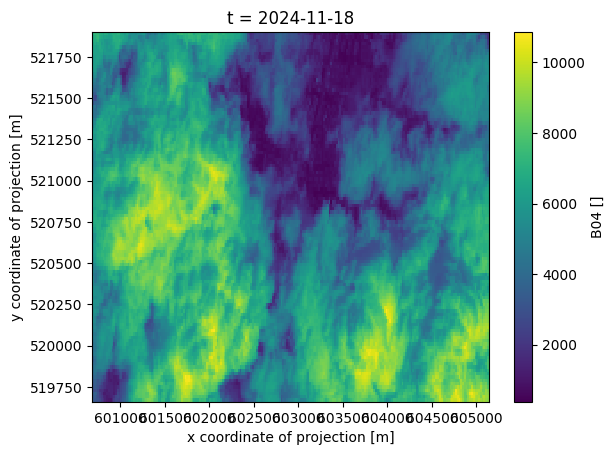

In [ ]:
np.random.seed(42)

idx = np.random.randint(low = 0, high = len(ds["t"]))
ds[{"t": idx}]["B04"].plot()

# 3. Visualization

## 3.1 RGB

Let's define a list of dates to be observed from the available dates that where saved in the `ds["t"]` dimension (Check the 2.2 subsection where we defined this dimension).

In [ ]:
dates_to_obs = [location_data["obs_date"]]

# dates_to_obs = [
#               "2024-10-14",
#               "2024-10-17"
#               ]

It's necessary to define a minmax normalization function for the data to be mapped to ubytes. Doing it will allow us to show the image from the location we are interested in, in the corresponding selected dates.

In [ ]:
def minmax(arr):
    min_val = np.nanmin(arr)
    max_val = np.nanmax(arr)
    return (arr - min_val)/(max_val - min_val)

Load the corresponding data to the R G B bands from the dataset:

- B04: Red
- B03: Green
- B02: Blue

In [ ]:
#Load the saved dataset
ds = xr.load_dataset(data_out)

#Select the bands
da_cube_rgb = ds[["B04", "B03", "B02"]].to_array(dim="bands").values
for bi in range(3):
    da_cube_rgb = np.moveaxis(da_cube_rgb, bi, bi+1)


def rgb_creation(selected_dates: list) -> np.ndarray:

    visual_indices = extract_indices(selected_dates)

    #Create an array to extract the dates RGB images from the dataset and save them in an RGB cube.
    cube_rgb = np.zeros((len(visual_indices), da_cube_rgb.shape[1], da_cube_rgb.shape[2], 3), dtype = np.int64)

    #Select the corresponding dates from the dataset and save them in the cube.
    for i in range(len(visual_indices)):
        t = visual_indices[i]
        cube_rgb[i] = img_as_ubyte(minmax(da_cube_rgb[t]))

    return cube_rgb

cube_rgb = rgb_creation(dates_to_obs)

Let's plot the selected dates. Define a variable `xy_axis` that will tell the plot if you want to put the image axis in latitude-longitude or in km (webmercator). Also, let's define a zoom variable for the obtained images in case you want to check less pixels around the zone. This zoom value divides the height and width by the value given, e.g if zoom = 2, then the image will have height and width divided by 2.

In [ ]:
xy_axis = "latit_longit"
zoom = 1

In [ ]:
#Obtain the height and width of the images in pixels
height = cube_rgb.shape[-3]
width = cube_rgb.shape[-2]

#Case of WebMercator axes
if xy_axis == "km":
    xmean = np.mean(x)/1000
    ymean = np.mean(y)/1000
    x_dist_range = (x[-1]-x[0])/2/zoom/1000
    y_dist_range = (y[-1]-y[0])/2/zoom/1000
    labels_x = np.round(np.linspace(-x_dist_range, x_dist_range,6), 3)
    labels_y = np.round(np.linspace(-y_dist_range, y_dist_range,6), 3)

#Case of EPSG:4326 axes
elif xy_axis == "latit_longit":
    xmean = (area_of_obs["west"]+ area_of_obs["east"])/2
    ymean = (area_of_obs["south"]+ area_of_obs["north"])/2
    x_dist_range = (area_of_obs["east"]- area_of_obs["west"])/2/zoom
    y_dist_range = (area_of_obs["north"]- area_of_obs["south"])/2/zoom
    labels_x = np.round(np.linspace(xmean-x_dist_range, xmean+x_dist_range,6), 3)
    labels_y = np.round(np.linspace(ymean-y_dist_range, ymean+y_dist_range,6), 3)
else:
    raise ValueError("xy_axis must be 'latit_longit' or 'km'")

#Define the data size applying the zoom

image_range_vertical = int(cube_rgb[0].shape[0]/2)
image_range_horizontal = int(cube_rgb[0].shape[1]/2)
upper_limit = height//2+int(image_range_vertical/zoom)
down_limit = height//2-int(image_range_vertical/zoom)
right_limit = width//2+int(image_range_horizontal/zoom)
left_limit = width//2-int(image_range_horizontal/zoom)

Location plotted!


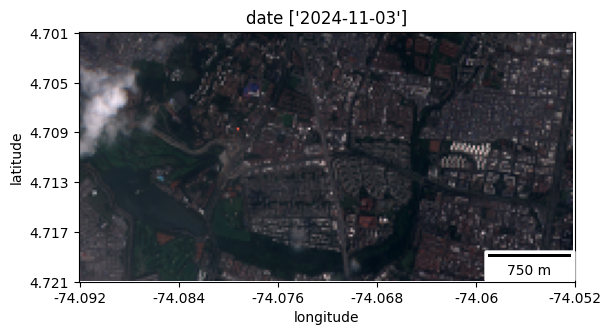

In [ ]:
#Generate an animation of the images
def animate(ni):
    visual_indices = extract_indices(dates_to_obs)

    index = visual_indices[ni]
    ax.imshow(cube_rgb[ni,down_limit:upper_limit,left_limit:right_limit])
    ax.set_xticks(np.linspace(0, width//(zoom), 6), labels_x)
    ax.set_yticks(np.linspace(0,height//(zoom),6), labels_y)
    ax.set_title(f"date {dates[index]}")

    if xy_axis == "latit_longit":
        ax.set_xlabel("longitude")
        ax.set_ylabel("latitude")
        scalebar = ScaleBar(resolution, "m", scale_loc = "bottom", location = "lower right")
        ax.add_artist(scalebar)

    if xy_axis == "km":
        ax.set_xlabel("Kilometers")
        ax.set_ylabel("Kilometers")
        scalebar = ScaleBar(resolution, "m", scale_loc = "bottom", location = "lower right")
        ax.add_artist(scalebar)

fig, ax = plt.subplots(figsize=(6, 5),layout='constrained')
frames = len(dates_to_obs)
animator = animation.FuncAnimation(fig, animate, frames=frames)
animator.save(images_out / "visualization.mp4")
display(HTML(animator.to_jshtml()))
print("Location plotted!")

## 4. Using already existing routines of OpenEO

Openeo has some already implemented routines to calculate indexes for different kind of visualizations. We will implement an NDVI index with one of this routines (you may check the other existing routines [here](https://processes.openeo.org/)).

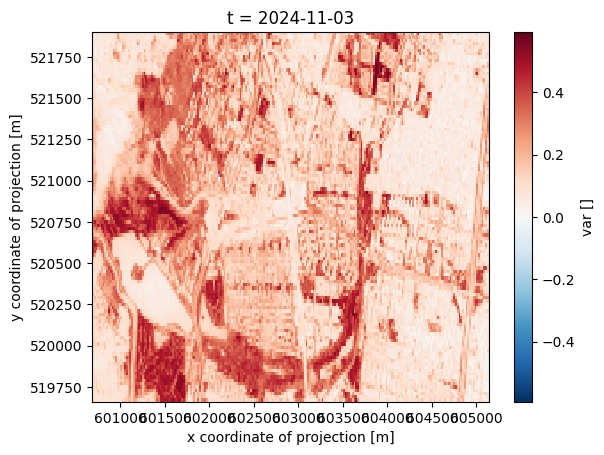

In [ ]:
ndvi_out = folder_out / (location_name+"_NDVI.nc")

if not os.path.exists(ndvi_out):
  s2_cube = ask_openeo(dates_range = dates_range,
                          area_of_obs = area_of_obs,
                          bands = ["B04", "B08"],
                          resolution = resolution)
  # Calculate NDVI
  ndvi = s2_cube.ndvi(nir="B08", red="B04")
  # Save the result to a netCDF4 file
  ndvi.download(ndvi_out, format="NetCDF")

# Load the netCDF4 file as an xarray dataset
ndvi_ds = xr.open_dataset(ndvi_out)

# Plot the NDVI
ndvi_ds[{"t": 0}]["var"][:,:].plot()

In [ ]:
ndvi_array = ndvi_ds['var']

test_index = 0
ndvi_image = ndvi_array[test_index,:,:].as_numpy()
# datetime in YY-MM-DD
ndvi_date = ndvi_array["t"].values[test_index]
timestamp = pd.Timestamp(ndvi_date)
ndvi_date = timestamp.strftime('%y-%m-%d')

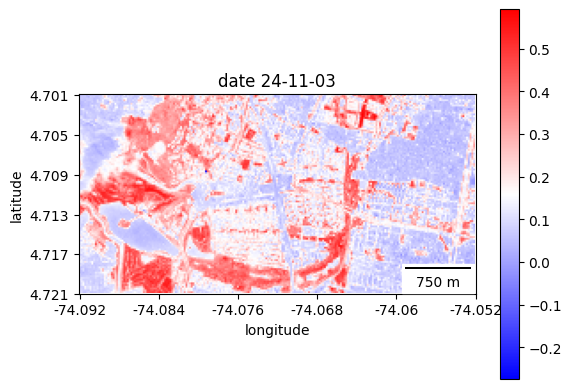

In [ ]:
#Generate an animation of the images
fig, ax = plt.subplots()
im = ax.imshow(ndvi_image, cmap="bwr")
ax.set_xticks(np.linspace(0, width//(zoom), 6), labels_x)
ax.set_yticks(np.linspace(0,height//(zoom),6), labels_y)
ax.set_title(f"date {ndvi_date}")

if xy_axis == "latit_longit":
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    scalebar = ScaleBar(resolution, "m", scale_loc = "bottom", location = "lower right")
    ax.add_artist(scalebar)

if xy_axis == "km":
    ax.set_xlabel("Kilometers")
    ax.set_ylabel("Kilometers")
    scalebar = ScaleBar(resolution, "m", scale_loc = "bottom", location = "lower right")
    ax.add_artist(scalebar)

fig.colorbar(im, ax = ax)
fig.show()